## Multi Species Model

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset, Dataset
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay
from pathlib import Path
import random
import json
import csv
from collections import Counter
from global_land_mask import globe
import h3
plt.style.use('ggplot')

In [2]:
# Global vars single species
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED = 0
INPUT_COLS = ["sin_lon", "cos_lon", "sin_lat", "cos_lat"]
NUM_INPUTS = len(INPUT_COLS)
NUM_EPOCHS = 27
LEARNING_RATE = 5e-3
CRITERION = nn.BCEWithLogitsLoss(reduction='none') #reduction = none prevents the batch average, preserves shape.
BATCH_SIZE = 512
NUM_HIDDEN_LAYERS = 3
HIDDEN_DIM = 128
RESULTS_DIR = Path.cwd()
COMMON_SETTINGS = {
    'seed': SEED, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'num_epochs': NUM_EPOCHS,
}
LABEL_SMOOTHING = 0.0
DROPOUT_KEEP = 0.85

### preprocess_cells.py

In [3]:

SEED=0
res=4
Abs_per_presence=1

# Load training data
train = np.load('species/species_train.npz')

# Grid- every H3 cell on the globe
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
grid = np.array([h3.cell_to_latlng(c) for c in grid_cells]) # centers
cell_index = {c: i for i, c in enumerate(grid_cells)}
print('Grid cells-', len(grid))

df = pd.DataFrame({'lat': train['train_locs'][:, 0], 'lon': train['train_locs'][:, 1], 'species': train['train_ids'],})
print('Sightings-', len(df))

def near_land(lat, lon, step=.25): # .25 d- about 28km N-S
    near = np.zeros(len(lat), dtype=bool)
    for dlat in (-step, 0, step):
        for dlon in (-step, 0, step):
            clip_lat = np.clip(lat+dlat,-90,90)
            clip_long = np.clip(lon+dlon,-180,180)
            near |= globe.is_land(clip_lat, clip_long)
    return near

# Remove ocean sightings- about 25km from land
df = df[near_land(df['lat'].values, df['lon'].values)].copy()
print('Total after removing ocean sightings-', len(df))
land_cells = np.flatnonzero(near_land(grid[:, 0], grid[:, 1]))
print('Land cells-', len(land_cells))

# Bin- find the H3 cell each sighting falls in
df['cell'] = [cell_index[h3.latlng_to_cell(lat, lon, res)] for lat, lon in zip(df['lat'], df['lon'])]

# Index for species 0-499
species_index = {taxon: i for i, taxon in enumerate(train['taxon_ids'])}
df['index'] = df['species'].map(species_index)

# Presence only- one row per cell, list of species seen there
presences = df.groupby('cell')['index'].unique().apply(sorted).reset_index(name='species')
presences['n_sightings'] = df.groupby('cell').size().values
print('Cells with sightings-', len(presences))

# Pseudo-absences- per species
rng = np.random.default_rng(SEED)
pairs = df[['cell', 'species']].drop_duplicates()  # one row per (cell, species) presence
absent_cells = []
absent_species = []
for species, group in pairs.groupby('species'):
    candidates = np.setdiff1d(land_cells, group['cell'])  # Pseudo-absences in cells where presences are not there
    picked = rng.choice(candidates, len(group)*Abs_per_presence, replace=False)
    absent_cells.extend(picked)
    absent_species.extend([species_index[species]] * len(picked))

# One row per cell, with the list of species pseudo-absence
absences = pd.DataFrame({'cell': absent_cells, 'absent': absent_species})
absences = absences.groupby('cell')['absent'].apply(list).reset_index()
absences['species'] = [[] for _ in range(len(absences))]  # no species seen
absences['n_sightings'] = 0

data = pd.concat([presences, absences], ignore_index=True)
data['absent'] = [a if type(a) == list else [] for a in data['absent']]
data['n_species'] = data['species'].apply(len)
print('Pseudo-absences-', len(absent_cells)) # Number of pseudo absences

# Taxonomy class for species
taxonomy = pd.read_csv('species/species_taxonomy.csv')
species_class = dict(zip(taxonomy['taxon_id'], taxonomy['class']))

# Number for each class
# {0: 'Amphibia', 1: 'Aves', 2: 'Crocodylia', 3: 'Mammalia', 4: 'Squamata', 5: 'Testudines'}
class_names = sorted(taxonomy['class'].unique())
class_index = {}
for i, c in enumerate(class_names):
    class_index[c] = i
class_id = []
for t in train['taxon_ids']:
    class_id.append(class_index[species_class[t]])
class_id = np.array(class_id)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

X_train = encode(grid[data['cell']])
y_train = np.zeros((len(data), len(species_index)), dtype=bool) # 1=species present
for row, species in enumerate(data['species']):
    y_train[row, species] = 1

absent_train = np.zeros((len(data), len(species_index)), dtype=bool)
for row, absent in enumerate(data['absent']):
    absent_train[row, absent] = 1

# Save
np.savez('species/preprocessed_cells.npz', X_train=X_train, y_train=y_train, absent_train=absent_train, class_id=class_id, n_sightings=data['n_sightings'].values, n_species=data['n_species'].values, cell_train=data['cell'].values, grid_latlon=grid, grid_cells=np.array(grid_cells), res=res, taxon_ids=train['taxon_ids'])
print('X_train-', X_train.shape, ', y_train-', y_train.shape)

# Usage for models
preprocessed = np.load('species/preprocessed_cells.npz')
cols = ['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']
train_df = pd.DataFrame(preprocessed['X_train'], columns=cols)
train_df['cell'] = preprocessed['cell_train']
train_df['n_species'] = preprocessed['n_species']
train_df['sightings'] = preprocessed['n_sightings']
train_df['species'] = [np.flatnonzero(row) for row in preprocessed['y_train']] # list view

X = preprocessed['X_train']
y = preprocessed['y_train'].astype(np.float32) # for NN, 0/1 col for each grid cell for all 500 species

# NaN 1=present, 0=absent, NaN=unknown 
y_nan = y.copy()
y_nan[(y_nan == 0) & ~preprocessed['absent_train']] = np.nan
print('present-', (y_nan == 1).sum(), 'absent-', (y_nan == 0).sum(), 'unknown-', np.isnan(y_nan).sum())

print(train_df.head())
print(f'X shape = {X.shape}')
print(f'y shape = {y_nan.shape}')
print(X[2], y_nan[2])

Grid cells- 288122
Sightings- 272037
Total after removing ocean sightings- 271239
Land cells- 89277
Cells with sightings- 16919
Pseudo-absences- 69497
X_train- (65215, 4) , y_train- (65215, 500)
present- 69497 absent- 69497 unknown- 32468506
    sin_lon   cos_lon   sin_lat   cos_lat  cell  n_species  sightings  \
0  0.517536  0.855661  0.632448 -0.774602  1671          1          1   
1  0.491174  0.871061  0.637845 -0.770165  1701          1          1   
2  0.474143  0.880448  0.636310 -0.771434  1706          4         26   
3 -0.866532 -0.499122  0.554682 -0.832062  3171          1          1   
4 -0.966489 -0.256710  0.667645 -0.744480  3499          1          1   

              species  
0               [111]  
1               [111]  
2  [25, 60, 227, 446]  
3               [437]  
4               [437]  
X shape = (65215, 4)
y shape = (65215, 500)
[ 0.47414342  0.88044762  0.63630974 -0.77143368] [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan

### worldclim_preprocess.py

In [4]:
import numpy as np
import pandas as pd
from global_land_mask import globe
#pip install rasterio
import rasterio
import rasterio.features
import rasterio.warp
import h3

def near_land(lat, lon, step=.25): # .25 d- about 28km N-S
    near = np.zeros(len(lat), dtype=bool)
    for dlat in (-step, 0, step):
        for dlon in (-step, 0, step):
            clip_lat = np.clip(lat+dlat,-90,90)
            clip_long = np.clip(lon+dlon,-180,180)
            near |= globe.is_land(clip_lat, clip_long)
    return near

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

def convert_tif_to_lonlat(file_name, bio_clim):
    
    data = rasterio.open(f"wc2.1_10m_bio/{file_name}")

    band1 = data.read(1)
    
    # create columns and rows (0 to 1079 and 0 to 2159)
    col = np.arange(data.width)
    row = np.arange(data.height)
    
    # create the column and row grid
    col_grid, row_grid = np.meshgrid(col, row)
    
    # take the latitude and longitude (add by 0.5 to get the center and not the top left corner)
    lon, lat = data.transform * (col_grid + 0.5, row_grid + 0.5)
    
    data_bio = []
    for i in row:
        for j in col:
            data_bio.append([lon[i, j], lat[i, j], band1[i, j]])
    
    data_bio = pd.DataFrame(data_bio, columns=['lon', 'lat', bio_clim])

    data.close()

    return data_bio

# Load all selected bioclim data
data_bio_1 = convert_tif_to_lonlat('wc2.1_10m_bio_1.tif', 'Annual Mean Temperature')
data_bio_4 = convert_tif_to_lonlat('wc2.1_10m_bio_4.tif', 'Temperature Seasonality')
data_bio_5 = convert_tif_to_lonlat('wc2.1_10m_bio_5.tif', 'Max Temperature of Warmest Month')
data_bio_6 = convert_tif_to_lonlat('wc2.1_10m_bio_6.tif', 'Min Temperature of Coldest Month')
data_bio_12 = convert_tif_to_lonlat('wc2.1_10m_bio_12.tif', 'Annual Precipitation')
data_bio_15 = convert_tif_to_lonlat('wc2.1_10m_bio_15.tif', 'Precipitation Seasonality')
data_bio_17 = convert_tif_to_lonlat('wc2.1_10m_bio_17.tif', 'Precipitation of Driest Quarter')
elev_data = convert_tif_to_lonlat('wc2.1_10m_elev.tif', 'Elevation')

# Column names
col_names = ['Annual Mean Temperature',
            'Temperature Seasonality',
             'Max Temperature of Warmest Month',
             'Min Temperature of Coldest Month',
             'Annual Precipitation',
             'Precipitation Seasonality',
             'Precipitation of Driest Quarter',
             'Elevation']

data_var = [data_bio_1, data_bio_4, data_bio_5, data_bio_6, data_bio_12, data_bio_15, data_bio_17, elev_data]

# make one table for all the bioclim data
data_bioclim = data_bio_1[['lon', 'lat']].copy()
for i in range(len(col_names)):
    col = col_names[i]
    var = data_var[i]
    data_bioclim[col] = var[col].values

# Remove worldclim cells- about 25km from land
data_bioclim = data_bioclim[near_land(data_bioclim['lat'].values, data_bioclim['lon'].values)].copy()

# drop the data that have no values (WorldClim uses -3.4e38 (bioclim) and -32768 (elevation))
data_bioclim[col_names] = data_bioclim[col_names].mask(data_bioclim[col_names] < -9999)
data_bioclim = data_bioclim.dropna(subset=col_names)

# remove polar edge cells with zero temperature seasonality
data_bioclim = data_bioclim[data_bioclim['Temperature Seasonality'] > 0]


data_bioclim[['sin_lon', 'cos_lon', 'sin_lat', 'cos_lat']] = encode(data_bioclim[['lat', 'lon']].values)

# Normalize the bioclim data
for i in range(len(col_names)):
    col = col_names[i]
    mu = data_bioclim[col].mean()
    sigma = data_bioclim[col].std()
    data_bioclim[col] = (data_bioclim[col] - mu) / sigma

res = 4

# Grid- every H3 cell on the globe
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
grid = np.array([h3.cell_to_latlng(c) for c in grid_cells])
cell_index = {c: i for i, c in enumerate(grid_cells)}

# H3 cell of every WorldClim cell
data_bioclim['cell'] = [cell_index[h3.latlng_to_cell(lat, lon, res)] for lat, lon in zip(data_bioclim['lat'], data_bioclim['lon'])]

# Average per hexagon
bioclim_h3 = data_bioclim.groupby('cell')[col_names].mean()

# One row per grid cell, same order as grid (NaN = no climate data)
env_grid = bioclim_h3.reindex(np.arange(len(grid))).values

np.savez('bioclim_h3_res4.npz',
         env_grid=env_grid,
         grid_cells=np.array(grid_cells),
         env_names=np.array(col_names),
         res=res)

print(env_grid)

# Load the preprocessed cells
preprocessed = np.load('species/preprocessed_cells.npz')
y_train = preprocessed['y_train']
absent_train = preprocessed['absent_train']

cols = ['sin_lon',
        'cos_lon',
        'sin_lat',
        'cos_lat'
       ]

# Column names
env_cols = ['Annual Mean Temperature',
            'Temperature Seasonality',
             'Max Temperature of Warmest Month',
             'Min Temperature of Coldest Month',
             'Annual Precipitation',
             'Precipitation Seasonality',
             'Precipitation of Driest Quarter',
             'Elevation']

# Make the train df from the preprocessed cells
train_df_bio = pd.DataFrame(preprocessed['X_train'], columns=cols)
train_df_bio['cell'] = preprocessed['cell_train']

# climate for each cell
train_df_bio[env_cols] = env_grid[train_df_bio['cell'].values]

# Drop cells with no climate data (ocean)
clean_bio = train_df_bio[env_cols].notna().all(axis=1).values
train_df_bio = train_df_bio[clean_bio]

X_train_bio = train_df_bio[cols + env_cols].values
y_train_bio = y_train[clean_bio]
X_train_bio_only = train_df_bio[env_cols].values
y_train_bio_only = y_train[clean_bio]
absent_train_bio = absent_train[clean_bio]

# Save
np.savez('preprocessed_cells_bio.npz', X_train=X_train_bio, X_train_bio_only=X_train_bio_only, y_train=y_train_bio, absent_train=absent_train_bio)
print('X_train_bio-', X_train_bio.shape, ', y_train_bio-', y_train_bio.shape)
print('X_train_bio_only-', X_train_bio_only.shape, ', y_train_bio_only-', y_train_bio_only.shape)

[[        nan         nan         nan ...         nan         nan
          nan]
 [        nan         nan         nan ...         nan         nan
          nan]
 [        nan         nan         nan ...         nan         nan
          nan]
 ...
 [-1.06567967 -0.18880968 -1.30297899 ...  0.59346682 -0.55213386
   0.60187424]
 [-0.90212864 -0.17436935 -1.13478529 ...  0.25643024 -0.55719858
   0.09518515]
 [-1.12526429 -0.15604131 -1.35607529 ...  0.93799406 -0.55761719
   0.75191713]]
X_train_bio- (64476, 12) , y_train_bio- (64476, 500)
X_train_bio_only- (64476, 8) , y_train_bio_only- (64476, 500)


In [5]:
#Train validation split
def training_set_inputs(set='bio_coords'):
    bio_data = np.load('preprocessed_cells_bio.npz')
    if set == 'bio_coords':
        X_new = bio_data['X_train']        
    elif set == 'bio':
        X_new = bio_data['X_train_bio_only']
    else:
        return X, y_nan
    y_new = bio_data['y_train'].astype(np.float32)
    y_nan_new = y_new.copy()
    y_nan_new[(y_nan_new == 0) & ~bio_data['absent_train']] = np.nan
    return X_new, y_nan_new, 

X, y_nan = training_set_inputs(set='coords') # Location only: coords. Bio + location: bio_coords. Bio only: bio
NUM_INPUTS = X.shape[1]
print(f'Dataset inputs: {NUM_INPUTS}')

# Stratify criteria - 0 species present (pseudo absences), 1, 2, 3, 4, or >5 species present (6 categories to stratify on)
# Ensures equal presences and absences in each set.
stratify_criteria = np.clip((y_nan == 1 ).sum(axis=1), 0, 5)
X_train, X_valid, y_train, y_valid = train_test_split(X, y_nan, test_size=0.25, random_state=SEED, shuffle=True, stratify=stratify_criteria)


# Mask to ignore un-observed species.
train_mask = y_train.copy()
train_mask[train_mask == 0.0] = 1.0
train_mask[np.isnan(train_mask)] = 0.0

valid_mask = y_valid.copy()
valid_mask[valid_mask == 0.0] = 1.0
valid_mask[np.isnan(valid_mask)] = 0.0

# Smooth absences with weighting
y_train[y_train == 0.0] = LABEL_SMOOTHING
y_valid[y_valid == 0.0] = LABEL_SMOOTHING

# Remove nans
X_train[np.isnan(X_train)] = 0.0
X_valid[np.isnan(X_valid)] = 0.0
y_train[np.isnan(y_train)] = 0.0
y_valid[np.isnan(y_valid)] = 0.0


def inputs_targets(which_X, which_y, which_mask):
    
    inputs = torch.from_numpy(which_X).to(torch.float32).to(DEVICE)
    targets = torch.from_numpy(which_y).to(torch.float32).to(DEVICE)
    mask = torch.from_numpy(which_mask).to(torch.float32).to(DEVICE)
    return TensorDataset(inputs, targets, mask)



Dataset inputs: 4


In [6]:
#data loaders

def make_data_loaders(X_train, y_train, train_mask, X_valid, y_valid, valid_mask, batch_size=BATCH_SIZE, seed=SEED):
    train_gen = torch.Generator().manual_seed(seed)
    train_dataloader = DataLoader(inputs_targets(X_train, y_train, train_mask), batch_size=batch_size,
                            shuffle=True, generator=train_gen)
    valid_dataloader = DataLoader(inputs_targets(X_valid, y_valid, valid_mask), batch_size=batch_size,
                                shuffle=False, generator=train_gen)
    return train_dataloader, valid_dataloader 

   

In [7]:
class MultiSpeciesMLP(nn.Module):
    def __init__(
            self, num_species=500, num_inputs=NUM_INPUTS,
            num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM,
            activation=nn.ReLU, dropout_keep=DROPOUT_KEEP):
        
        super().__init__()
        self.num_inputs = num_inputs
        self.num_hidden_layers = num_hidden_layers
        self.hidden_dim = hidden_dim
        
        layers = []
        input_dim = num_inputs
        for _ in range(num_hidden_layers):
            layers.append(nn.Linear(input_dim, hidden_dim))
            if dropout_keep is not None:
                layers.append(nn.Dropout(p=1.0 - dropout_keep))
            layers.append(activation())
            input_dim = hidden_dim

        layers.append(nn.Linear(input_dim, num_species))
        self.model = nn.Sequential(*layers)
        for layer in self.model.modules():
            if isinstance(layer, nn.Linear):
                nn.init.xavier_uniform_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, inputs):
        return self.model(inputs)


In [8]:
def masked_loss(logits, targets, mask, criterion=CRITERION):
    loss = criterion(logits, targets)
    return (loss * mask).sum() / mask.sum()

def evaluate (model, data_loader, criterion=CRITERION, threshold=0.5, pr_curve=False):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_examples = 0
    # Collect outputs for metrics
    logits_all = []
    targets_all = []
    mask_all = []
    

    with torch.no_grad():
        for inputs, targets, mask in data_loader:
            inputs = torch.as_tensor(inputs)
            logits = torch.as_tensor(model(inputs))
            targets = torch.as_tensor(targets)
            mask = torch.as_tensor(mask)
            threshold = torch.as_tensor(threshold)
            total_loss += (criterion(logits, targets) * mask).sum().item()
            # Include threshold
            logits_prob = torch.sigmoid(logits)
            predict = (logits_prob >= threshold).to(targets.dtype)
            total_correct += ((predict==targets) * mask).sum().item()
            total_examples += mask.sum().item()

            logits_all.append(logits)
            targets_all.append(targets)
            mask_all.append(mask)
            

    probabilities = torch.sigmoid(torch.cat(logits_all)).cpu().numpy()
    true_out = torch.cat(targets_all).cpu().numpy()
    mask_out = torch.cat(mask_all).cpu().numpy().astype(bool)
    
    auc_per_species =np.full(true_out.shape[1], np.nan)
    ap_per_species = np.full(true_out.shape[1], np.nan)

    for species in range(true_out.shape[1]):
        mask = mask_out[:, species]
        targs = true_out[mask, species]
        probs = probabilities[mask, species]
        if len(np.unique(targs)) < 2:
            continue
        auc_per_species[species] = roc_auc_score(targs, probs)
        ap_per_species[species] = average_precision_score(targs, probs)

    macro_auc = float(np.nanmean(auc_per_species)) # Unweighted average auc
    macro_map = float(np.nanmean(ap_per_species))  # Unweighted map

    loss_ave = total_loss / total_examples
    accuracy = total_correct / total_examples
    curve_data = {
        'auc_per_species': np.asarray(auc_per_species),
        'ap_per_species': np.asarray(ap_per_species),
        'macro_auc': macro_auc,
        'macro_map': macro_map,
    }          
    if pr_curve:
        precision, recall, thresholds = precision_recall_curve(true_out[mask_out], probabilities[mask_out])
        micro_ap = float(average_precision_score(true_out[mask_out], probabilities[mask_out]))   # weighted average precision
        curve_data['precision'] = precision
        curve_data['recall'] = recall
        curve_data['thresholds'] = thresholds
        curve_data['micro_ap'] = micro_ap
   
    
            
    return loss_ave, accuracy, curve_data

def train_model(model, train_data, valid_data,
                num_epochs=NUM_EPOCHS, stats_interval=1, learning_rate=LEARNING_RATE,
                criterion=CRITERION, eval_criterion=CRITERION, regularizer=None):
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss(reduction='none')
    if eval_criterion is None:
        eval_criterion = nn.BCEWithLogitsLoss(reduction='none')
    
    optimiser = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=3e-4)
    stats =[]
    
    gradient_history = []

    train_loss, train_acc, train_curves = evaluate(model, train_data, eval_criterion)
    valid_loss, valid_acc, valid_curves = evaluate(model, valid_data, eval_criterion)
    stats.append([train_loss, valid_loss, train_acc, valid_acc, train_curves['macro_auc'], valid_curves['macro_auc'],
                train_curves['macro_map'], valid_curves['macro_map']])
    

    for epoch in range(1, num_epochs + 1):
        model.train()
        first_batch_gradients = None
        for inputs, targets, mask in train_data:
            optimiser.zero_grad()
            logits = model(inputs)
            loss = masked_loss(logits, targets, mask)
            if regularizer is not None:
                loss = loss + regularizer(model)
            loss.backward()
            if first_batch_gradients is None:
                first_batch_gradients = [
                    parameter.grad.detach().abs().mean().item()
                    if parameter.grad is not None else 0.0
                    for parameter in model.parameters() if parameter.requires_grad
                ]
            optimiser.step()
        gradient_history.append(first_batch_gradients)

        if epoch % stats_interval==0:
            train_loss, train_acc, train_curves= evaluate(model, train_data, eval_criterion)
            valid_loss, valid_acc, valid_curves= evaluate(model, valid_data, eval_criterion)
            stats.append([train_loss, valid_loss, train_acc, valid_acc, train_curves['macro_auc'], valid_curves['macro_auc'],
                train_curves['macro_map'], valid_curves['macro_map']])
            
    stats = np.asarray(stats)
    
    _, _, valid_pr_curve = evaluate(model, valid_data, eval_criterion, pr_curve=True)


    
    
    gradient_history = np.asarray(gradient_history)
    keys = {'train_error' : 0, 'valid_error' : 1,
            'train_acc' : 2, 'valid_acc' : 3,
            'train_auc': 4, 'valid_auc': 5,
            'train_map': 6, 'valid_map': 7
            }

    return stats, keys, gradient_history, valid_pr_curve
            




In [9]:
def decimal(param):
    return f'{param:.10f}'.rstrip("0").rstrip(".")
    
def name_builder(num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM, label_smoothing=None, dropout_keep=DROPOUT_KEEP, regularizer=None):
    '''Run name creation for naming of files with associated settings'''
    name_parts = [f'multi_sp_depth_{num_hidden_layers}', f'width_{hidden_dim}', f'inputs_{NUM_INPUTS}', f'epochs_{NUM_EPOCHS}']

    if dropout_keep is not None:
        name_parts.append(f'dropout_{dropout_keep}')
    if label_smoothing is not None:
        name_parts.append(f'smoothing_{label_smoothing}')
    if regularizer is not None:
        if regularizer.lambda_1 > 0.0 and regularizer.lambda_2 > 0.0:
            name_parts.append(f'elastic_lam1_{decimal(regularizer.lambda_1)}_lam2_{decimal(regularizer.lambda_2)}')
        elif regularizer.lambda_1 == 0.0 and regularizer.lambda_2 > 0.0:
            name_parts.append(f'l2_lambda2_{decimal(regularizer.lambda_2)}')
        elif regularizer.lambda_1 > 0.0 and regularizer.lambda_2 == 0.0:
            name_parts.append(f'l1_lambda1_{decimal(regularizer.lambda_1)}')
            
    
    return "__".join(name_parts) #f'depth{num_hidden_layers}_width{hidden_dim}'

def load_run(name):
    '''Load a saved run'''
    data = np.load(RESULTS_DIR/f'{name}.npz', allow_pickle=True)

    return {'name': name, 'stats': data['stats'], 'gradients': data['gradients'], 'curve_data' : data['curve_data'],
            'parameter_names': [str(i) for i in data['parameter_names']], 'config': json.loads(str(data['config']))}
    

In [10]:
def reset_seeds():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

def run_experiment(data_loader, num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM,  label_smoothing=None, dropout_keep=DROPOUT_KEEP, regularizer=None, overwrite=False):
    """Train a fresh seeded model."""
    lambda_1 = regularizer.lambda_1 if regularizer is not None else 0.0
    lambda_2 = regularizer.lambda_2 if regularizer is not None else 0.0
    
    config = dict(
        COMMON_SETTINGS, num_hidden_layers=num_hidden_layers, hidden_dim=hidden_dim,
        label_smoothing=label_smoothing, dropout_keep=dropout_keep, lambda_1=lambda_1, lambda_2=lambda_2)


    name = name_builder(num_hidden_layers, hidden_dim, label_smoothing, dropout_keep, regularizer)
    result_path = RESULTS_DIR / f'{name}.npz'

    if result_path.exists() and not overwrite:
        existing_result = load_run(name)
        assert existing_result['config'] == json.loads(json.dumps(config)), f'{name}: saved settings differ from those requested. Re-run with overwrite=True to replace'
        print(f'Results loaded for {name}', flush=True)
        return existing_result
              
    
    reset_seeds()
    
    
        
    train_loader, valid_loader = data_loader 
    model = MultiSpeciesMLP().to(DEVICE)

    print(f'Training {name} on {DEVICE}: seed={SEED}, epochs={NUM_EPOCHS}', flush=True)
    stats, _, gradients, curves = train_model(
        model, train_loader, valid_loader, num_epochs=NUM_EPOCHS,
        stats_interval=1, learning_rate=LEARNING_RATE, regularizer=regularizer)
    assert stats.shape == (NUM_EPOCHS + 1, 8) and np.isfinite(stats).all()
    parameter_names = [name for name, parameter in model.named_parameters()
                       if parameter.requires_grad]
    torch.save(model.state_dict(), RESULTS_DIR / f'{name}_weights.pt')
    np.savez(result_path, stats=stats, gradients=gradients, curves=curves,
             parameter_names=np.asarray(parameter_names), config=json.dumps(config, sort_keys=True))
    print(f'Finished {name}: validation accuracy={stats[-1, 3]:.2%}', flush=True)
    return {'name': name, 'stats': stats, 'gradients': gradients, 'curve_data': curves,
            'parameter_names': parameter_names, 'config': config}

def export_table(results, csv_name, parameter_label):
    """Report epoch-100 metrics, with validation accuracy in percent."""
    rows = []
    print(f'{parameter_label:>13} | Val. accuracy (%) | Train CE | Valid CE | Gen Gap | Val AUC | Val MAP |')
    for parameter, result in results.items():
        final = result['stats'][-1]
        row = [parameter, 100 * final[3], final[0], final[1], final[1] - final[0], final[5], final[7]]
        rows.append(row)
        print(f'{parameter:>13} | {row[1]:17.2f} | {row[2]:8.4f} | {row[3]:8.4f} | {row[4]:8.4f} | {row[5]:8.4f} | {row[6]:8.4f} |')
    with (RESULTS_DIR / csv_name).open('w', newline='', encoding='utf-8') as handle:
        writer = csv.writer(handle)
        writer.writerow([parameter_label, 'validation_accuracy_percent',
                         'train_cross_entropy', 'validation_cross_entropy', 'generalisation_gap', 'validation_auc', 'validation_map'])
        writer.writerows(rows)
    return rows


In [11]:
data_loader = make_data_loaders(X_train, y_train, train_mask, X_valid, y_valid, valid_mask,)
multi_species_baseline = run_experiment(num_hidden_layers=NUM_HIDDEN_LAYERS, hidden_dim=HIDDEN_DIM, data_loader=data_loader, overwrite=True)


Training multi_sp_depth_3__width_128__inputs_4__epochs_27__dropout_0.85 on cuda: seed=0, epochs=27
Finished multi_sp_depth_3__width_128__inputs_4__epochs_27__dropout_0.85: validation accuracy=95.79%


In [12]:
def plot_learning_curves(results, save_prefix=None):
    """Plot stored metrics only; results maps model labels to experiment records."""
    loss_fig, loss_ax = plt.subplots(figsize=(6, 3.8))
    acc_fig, acc_ax = plt.subplots(figsize=(6, 3.8))
    auc_fig, auc_ax = plt.subplots(figsize=(6, 3.8))
    map_fig, map_ax = plt.subplots(figsize=(6, 3.8))
    colours = plt.rcParams['axes.prop_cycle'].by_key()['color']

    for index, (label, result) in enumerate(results.items()):
        values = result['stats']
        epochs = np.arange(1, len(values))  # Row zero is the untrained model.
        colour = colours[index % len(colours)]
        for ax, train_column, valid_column in ((loss_ax, 0, 1), (acc_ax, 2, 3)):
            ax.plot(epochs, values[1:, train_column], color=colour, label=f'{label} (train)')
            ax.plot(epochs, values[1:, valid_column], color=colour,
                    linestyle='--', label=f'{label} (valid)')
        for ax, train_column, valid_column in ((auc_ax, 4, 5), (map_ax, 6, 7)):
                    ax.plot(epochs, values[1:, train_column], color=colour, label=f'{label} (train)')
                    ax.plot(epochs, values[1:, valid_column], color=colour,
                            linestyle='--', label=f'{label} (valid)')
    for ax in (loss_ax, acc_ax):
        ax.set_xlabel('Epoch number')
        ax.legend(fontsize=9, ncol=2)
    for ax in (auc_ax, map_ax):
            ax.set_xlabel('Epoch number')
            ax.legend(fontsize=9, ncol=2)
    loss_ax.set_ylabel('BCE Logit loss')
    acc_ax.set_ylabel('Accuracy')
    auc_ax.set_ylabel('AUC')
    map_ax.set_ylabel('MAP')
    loss_fig.tight_layout()
    acc_fig.tight_layout()
    auc_fig.tight_layout()
    map_fig.tight_layout()
    if save_prefix is not None:
        save_prefix = Path(save_prefix)
        save_prefix.parent.mkdir(parents=True, exist_ok=True)
        loss_fig.savefig(f'{save_prefix}_loss.png', dpi=300, bbox_inches='tight')
        acc_fig.savefig(f'{save_prefix}_accuracy.png', dpi=300, bbox_inches='tight')
        auc_fig.savefig(f'{save_prefix}_auc.png', dpi=300, bbox_inches='tight')
        map_fig.savefig(f'{save_prefix}_map.png', dpi=300, bbox_inches='tight')
    return loss_fig, loss_ax, acc_fig, acc_ax, auc_fig, auc_ax, map_fig, map_ax

(<Figure size 600x380 with 1 Axes>,
 <Axes: xlabel='Epoch number', ylabel='BCE Logit loss'>,
 <Figure size 600x380 with 1 Axes>,
 <Axes: xlabel='Epoch number', ylabel='Accuracy'>,
 <Figure size 600x380 with 1 Axes>,
 <Axes: xlabel='Epoch number', ylabel='AUC'>,
 <Figure size 600x380 with 1 Axes>,
 <Axes: xlabel='Epoch number', ylabel='MAP'>)

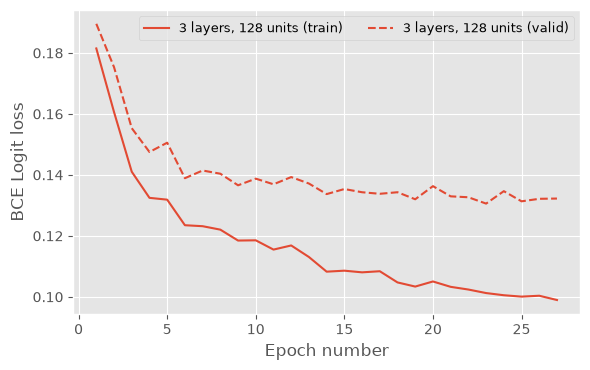

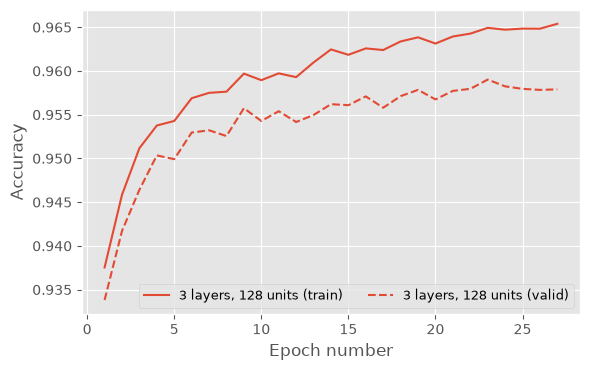

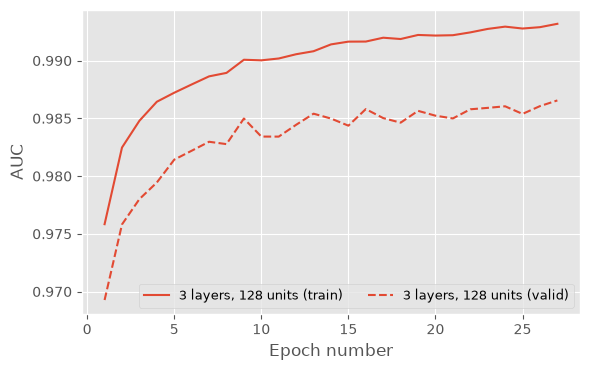

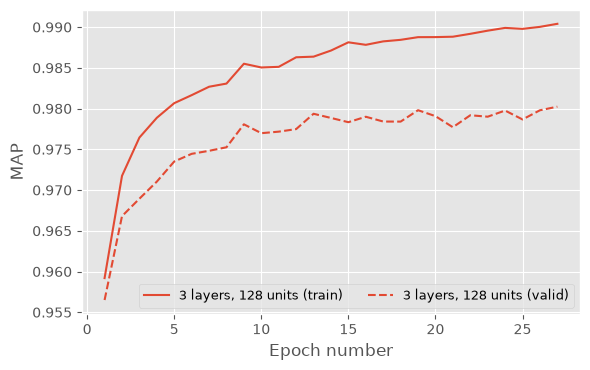

In [13]:
plot_learning_curves({f'{NUM_HIDDEN_LAYERS} layers, {HIDDEN_DIM} units': multi_species_baseline})

In [14]:
# Early stop cirteria for fixed network capacity - peak map
saved_full_run = np.load('multi_sp_depth_3__width_128__inputs_4__epochs_30__dropout_0.85.npz')
map_history = saved_full_run['stats'][1:, 7]
peak_map = np.max(map_history)
peak_map_epoch = np.argmax(map_history) + 1

print(f'Peak Validation MAP: {peak_map}')
print(f'At Epoch: {peak_map_epoch}')

Peak Validation MAP: 0.9802319698743175
At Epoch: 27


In [15]:
all_species = []
for entry in train_df["species"]:
    for species in entry:
        all_species.append(species)
counts = Counter(all_species)
# Most common
most_common = counts.most_common(1)[0]
# Least common
least_common = counts.most_common()[-1]
print(f"Most common: {most_common[0]} (appeared {most_common[1]} times)")
print(f"Least common: {least_common[0]} (appeared {least_common[1]} times)")

Most common: 414 (appeared 880 times)
Least common: 244 (appeared 3 times)


In [16]:
# Tained Model Inference
def multi_species_predict(model, input, batch_size=1024):
    model.eval()
    device = DEVICE
    prob = []

    with torch.no_grad():
        for i in range(0, len(input), batch_size):
            input_tens = torch.tensor(input[i : i+batch_size], dtype=torch.float32, device=device)
            prob.append(torch.sigmoid(model(input_tens)).cpu().detach().numpy())

    return np.vstack(prob)

    

In [19]:
# Thesholds optimised using TSS (true skill statistic = true pos rate - false pos rate)

model = MultiSpeciesMLP().to(DEVICE)
model.load_state_dict(torch.load(RESULTS_DIR / f"multi_sp_depth_3__width_128__inputs_4__epochs_27__dropout_0.85_weights.pt", map_location=DEVICE))
probs_valid = multi_species_predict(model, X_valid)

def optimise_thresholds_multi():
    
    thresholds = np.full(500, 0.5)
    for species in range(500):
        mask = valid_mask[:, species].astype(bool)
        targs = y_valid[mask, species]
        probs = probs_valid[mask, species]
        if (targs == 1).sum() <3 or (targs == 0).sum() < 3:
            continue

        false_pos_rate, true_pos_rate, threshold = roc_curve(targs, probs)
        true_skill_stat = true_pos_rate - false_pos_rate
        thresh_idx = int(np.argmax(true_skill_stat))
        if true_skill_stat[thresh_idx] > 0 and np.isfinite(threshold[thresh_idx]):
            thresholds[species] = threshold[thresh_idx]

    return thresholds

thresholds = optimise_thresholds_multi()

# Per species metrics

def per_species_metrics_multi(probs, targets, mask=None):
    stored_metrics = ('roc_auc', 'ave_pre', 'tss', 'sensitivity', 'specificity')
    metrics = {keys: np.full(500, np.nan) for keys in stored_metrics}
    conf_mat_plot = 500 * [None]

    for species in range(500):
        if mask is not None:
            mask_m = mask[:, species].astype(bool)
            targs = targets[mask_m, species].astype(int)
            probs_p = probs[mask_m, species]
        else:
            targs = targets[:, species].astype(int)
            probs_p = probs[:, species]
        if len(np.unique(targs)) < 2:
            continue

        predicts = (probs_p >= thresholds[species]).astype(int)
        conf_mat_plot[species] = ConfusionMatrixDisplay(confusion_matrix(targs, predicts, labels=[1, 0]), display_labels=['Presence = 1', 'Absence = 0'])
        tru_neg, fal_pos, fal_neg, tru_pos = confusion_matrix(targs, predicts, labels=[1, 0]).ravel()

        sensitivity = tru_pos / (tru_pos + fal_neg)
        specificity = tru_neg / (tru_neg + fal_pos)

        
        metrics['roc_auc'][species] = roc_auc_score(targs, probs_p)
        metrics['ave_pre'][species] = average_precision_score(targs, probs_p)
        metrics['tss'][species] = sensitivity + specificity - 1.0
        metrics['sensitivity'][species] = sensitivity
        metrics['specificity'][species] = specificity

    return metrics, conf_mat_plot




In [20]:
# Presence absence output
def presence_absence_multi(model, inputs, thresholds):
    probs = multi_species_predict(model, inputs)
    pres_abs = (probs >= thresholds).astype(int)
    
    return pres_abs

pres_abs_valid = presence_absence_multi(model, X_valid, thresholds)

In [21]:
print(probs_valid.shape)
print(y_valid.shape)
#print(thresholds.shape)

(16304, 500)
(16304, 500)


5th, 30th, 50th, and 90th percentile probability thresholds for presence: 
 [0.33529195 0.73202313 0.89675254 0.99900283]
----- Macro Stats (averaged over N species, ignores abundance) -------
Validation set Macro ROC-AUC (ignores aabundance): 0.9865532070075488
Validation set Macro Average Precision: 0.9802319698743175
Validation set Macro True Skill Statistic: 0.9553776063720665
Validation set Macro Sensitivity: 0.9627129526852451
Validation set Macro Specificity: 0.9926646536868213


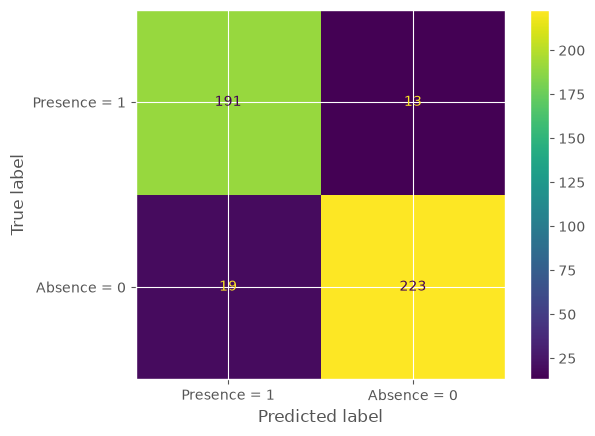

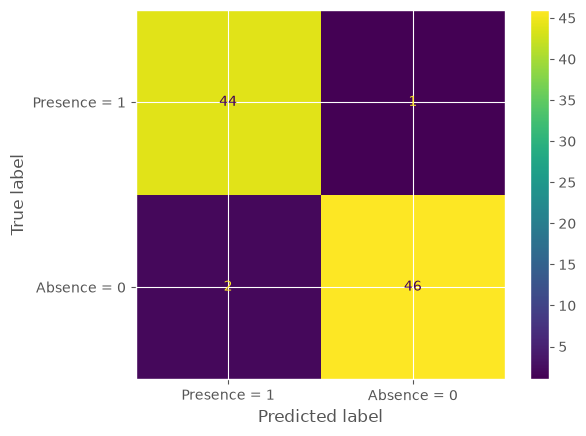

In [ ]:
# Validation set stats - location
print(f'5th, 30th, 50th, and 90th percentile probability thresholds for presence: \n {np.percentile(thresholds, [5, 30, 50, 90])}')
valid_metrics, valid_conf_mat = per_species_metrics_multi(probs_valid, y_valid, mask=valid_mask)
print(f'----- Macro Stats (averaged over N species, ignores abundance) -------')
print(f'Validation set Macro ROC-AUC (ignores aabundance): {np.nanmean(valid_metrics['roc_auc'])}')
print(f'Validation set Macro Average Precision: {np.nanmean(valid_metrics['ave_pre'])}')
print(f'Validation set Macro True Skill Statistic: {np.nanmean(valid_metrics['tss'])}')
print(f'Validation set Macro Sensitivity: {np.nanmean(valid_metrics['sensitivity'])}')
print(f'Validation set Macro Specificity: {np.nanmean(valid_metrics['specificity'])}')
# Confusion matrix for training set most common (414) and least common (214)
# Stratified so numbers don't confirm rarity
disp_common = valid_conf_mat[414]
disp_common.plot()
disp_rare = valid_conf_mat[214]
disp_rare.plot()

### preprocess_test.py

In [23]:
import numpy as np
import h3

test = np.load('species/species_test.npz', allow_pickle=True)

# Features- normalise lat/lon to [-1,1], then sin/cos (SINR paper approach)
def encode(latlon):
    lat = latlon[:,0]/90
    lon = latlon[:,1]/180
    return np.column_stack([np.sin(np.pi*lon), np.cos(np.pi*lon), np.sin(np.pi*lat), np.cos(np.pi*lat)])

res = 4
grid_cells = [c for r0 in h3.get_res0_cells() for c in h3.cell_to_children(r0, res)]
cell_index = {c: i for i, c in enumerate(grid_cells)}
cell_test= []
for lat, lon in test['test_locs'].astype(float):
    cell_test.append(cell_index[h3.latlng_to_cell(lat, lon, res)])
cell_test = np.array(cell_test)

X_test = encode(test['test_locs'])
y_test = np.zeros((len(X_test), len(test['taxon_ids'])), dtype=bool)
for i, pos in enumerate(test['test_pos_inds']):
    y_test[pos, i] = 1  # species i present at these locations, 0 elsewhere

print('X_test-', X_test.shape, ', y_test-', y_test.shape, ', cell_test-', cell_test.shape)

X_test- (288122, 4) , y_test- (288122, 500) , cell_test- (288122,)


In [25]:
# Run the model on the test set

multi_species_test = MultiSpeciesMLP().to(DEVICE)
multi_species_test.load_state_dict(torch.load('multi_sp_depth_3__width_128__inputs_4__epochs_27__dropout_0.85_weights.pt', map_location=DEVICE))
multi_species_test.eval()

# NEEDS TEST PRE-PROCESSING WITH ALONGSIDE BIO
# Load test data to X_test (shape (N, NUM_INPUTS)). Ensure no nans (set them to 0)

multi_species_test_probs = multi_species_predict(multi_species_test, X_test)
multi_species_test_pres_abs = presence_absence_multi(multi_species_test, X_test, thresholds)

5th, 30th, 50th, and 90th percentile probability thresholds for presence: 
 [0.33529195 0.73202313 0.89675254 0.99900283]
----- Macro Stats (averaged over N species, ignores abundance) -------
Test set Macro ROC-AUC (ignores aabundance): 0.9674508624094538
Test set Macro Average Precision: 0.17449601113370608
Test set Macro True Skill Statistic: 0.7312451176918948
Test set Macro Sensitivity: 0.9484813043372349
Test set Macro Specificity: 0.7827638133546599


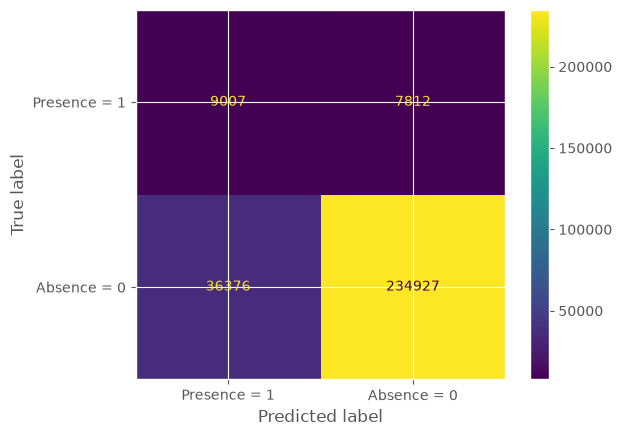

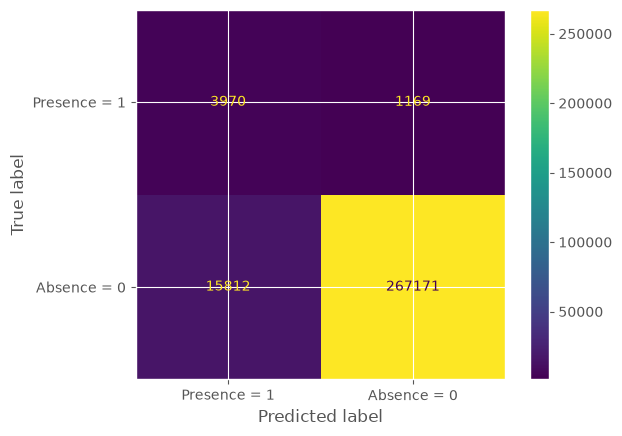

In [27]:
# Test set stats - location
print(f'5th, 30th, 50th, and 90th percentile probability thresholds for presence: \n {np.percentile(thresholds, [5, 30, 50, 90])}')
test_metrics, test_conf_mat = per_species_metrics_multi(multi_species_test_probs, y_test)
print(f'----- Macro Stats (averaged over N species, ignores abundance) -------')
print(f'Test set Macro ROC-AUC (ignores aabundance): {np.nanmean(test_metrics['roc_auc'])}')
print(f'Test set Macro Average Precision: {np.nanmean(test_metrics['ave_pre'])}')
print(f'Test set Macro True Skill Statistic: {np.nanmean(test_metrics['tss'])}')
print(f'Test set Macro Sensitivity: {np.nanmean(test_metrics['sensitivity'])}')
print(f'Test set Macro Specificity: {np.nanmean(test_metrics['specificity'])}')
# Confusion matrix for training set most common (414) and least common (214)
# Stratified so numbers don't confirm rarity
disp_common = test_conf_mat[414]
disp_common.plot()
disp_rare = test_conf_mat[214]
disp_rare.plot()